In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv("../dataset/Womens Clothing E-Commerce Reviews.csv")

# Display first 5 rows
df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [2]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (23486, 11)

Column Names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name         

In [3]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

Total Missing Values: 4697


In [4]:
# Fill missing text values
df['Title'] = df['Title'].fillna('No Title')

df['Review Text'] = df['Review Text'].fillna('No Review')

# Fill missing categorical values
df['Division Name'] = df['Division Name'].fillna('Unknown')
df['Department Name'] = df['Department Name'].fillna('Unknown')
df['Class Name'] = df['Class Name'].fillna('Unknown')

# Verify missing values
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Cleaning:
Unnamed: 0                 0
Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64

Total Missing Values: 0


In [ ]:
# Fill missing text values
df['Title'] = df['Title'].fillna('No Title')

df['Review Text'] = df['Review Text'].fillna('No Review')

# Fill missing categorical values
df['Division Name'] = df['Division Name'].fillna('Unknown')
df['Department Name'] = df['Department Name'].fillna('Unknown')
df['Class Name'] = df['Class Name'].fillna('Unknown')

# Verify missing values
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Cleaning:
Unnamed: 0                 0
Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64

Total Missing Values: 0


In [6]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 0


In [7]:
# Remove unnecessary index column
df.drop(columns=['Unnamed: 0'], inplace=True)

# Verify updated dataset
print("Updated Dataset Shape:", df.shape)

print("\nRemaining Columns:")
print(df.columns.tolist())

Updated Dataset Shape: (23486, 10)

Remaining Columns:
['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']


In [8]:
# Statistical summary
df.describe()

,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,918.118709,43.198544,4.196032,0.822362,2.535936
std,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,18.000000,1.000000,0.000000,0.000000
25%,861.000000,34.000000,4.000000,1.000000,0.000000
50%,936.000000,41.000000,5.000000,1.000000,1.000000
75%,1078.000000,52.000000,5.000000,1.000000,3.000000
max,1205.000000,99.000000,5.000000,1.000000,122.000000


In [9]:
# Count ratings
rating_counts = df['Rating'].value_counts().sort_index()

print("Rating Distribution:")
print(rating_counts)

Rating Distribution:
Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64


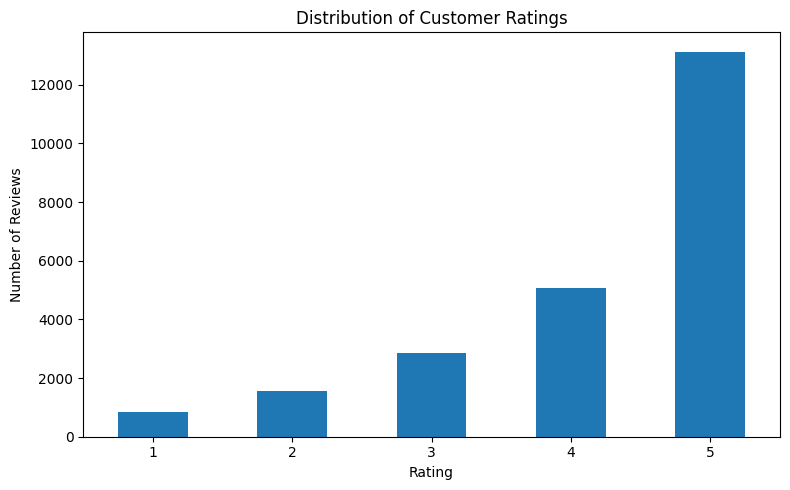

In [10]:
import matplotlib.pyplot as plt

rating_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('../outputs/rating_distribution.png')
plt.show()

In [11]:
recommend_counts = df['Recommended IND'].value_counts()

print("Recommendation Distribution:")
print(recommend_counts)

Recommendation Distribution:
Recommended IND
1    19314
0     4172
Name: count, dtype: int64


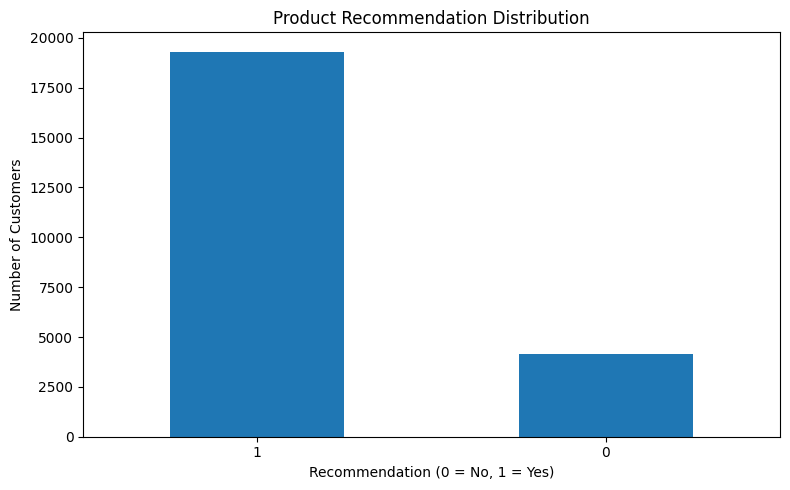

In [12]:
import matplotlib.pyplot as plt

recommend_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Product Recommendation Distribution')
plt.xlabel('Recommendation (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('../outputs/recommendation_distribution.png')
plt.show()

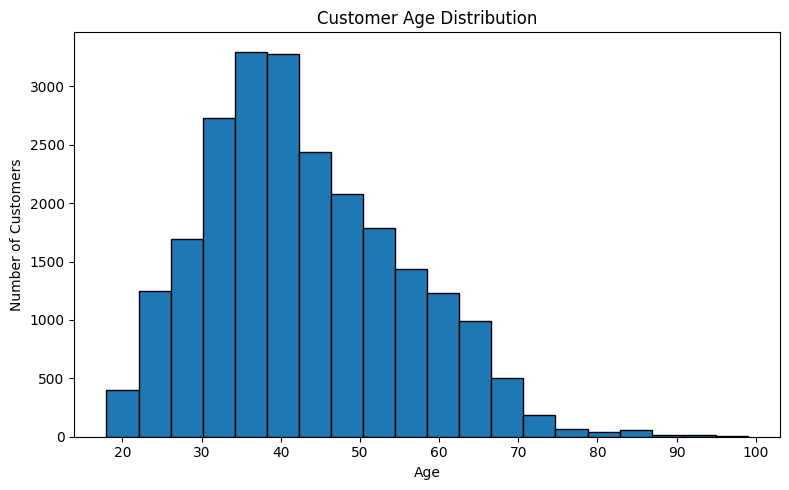

In [13]:
# Age distribution
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=20, edgecolor='black')

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.savefig('../outputs/age_distribution.png')
plt.show()

In [14]:
department_counts = df['Department Name'].value_counts()

print("Department-wise Reviews:")
print(department_counts)

Department-wise Reviews:
Department Name
Tops        10468
Dresses      6319
Bottoms      3799
Intimate     1735
Jackets      1032
Trend         119
Unknown        14
Name: count, dtype: int64


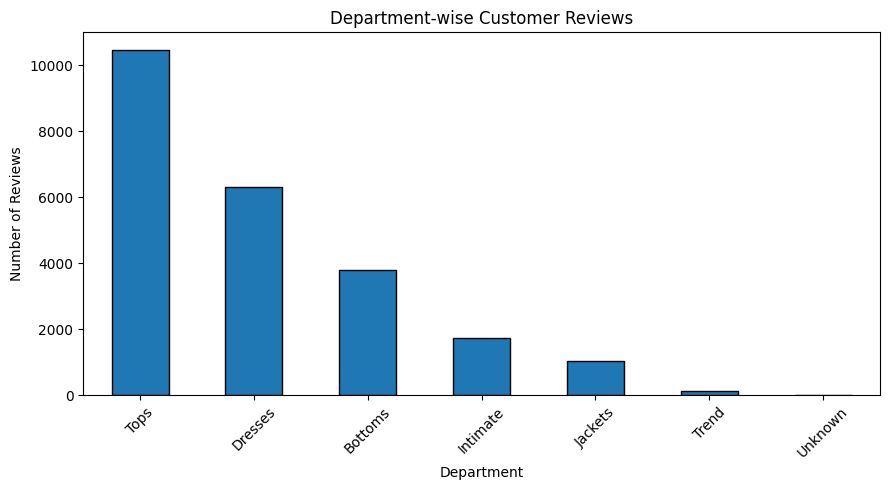

In [15]:
plt.figure(figsize=(9, 5))

department_counts.plot(kind='bar', edgecolor='black')

plt.title('Department-wise Customer Reviews')
plt.xlabel('Department')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../outputs/department_reviews.png')
plt.show()

In [16]:
division_counts = df['Division Name'].value_counts()

print("Division-wise Reviews:")
print(division_counts)

Division-wise Reviews:
Division Name
General           13850
General Petite     8120
Initmates          1502
Unknown              14
Name: count, dtype: int64


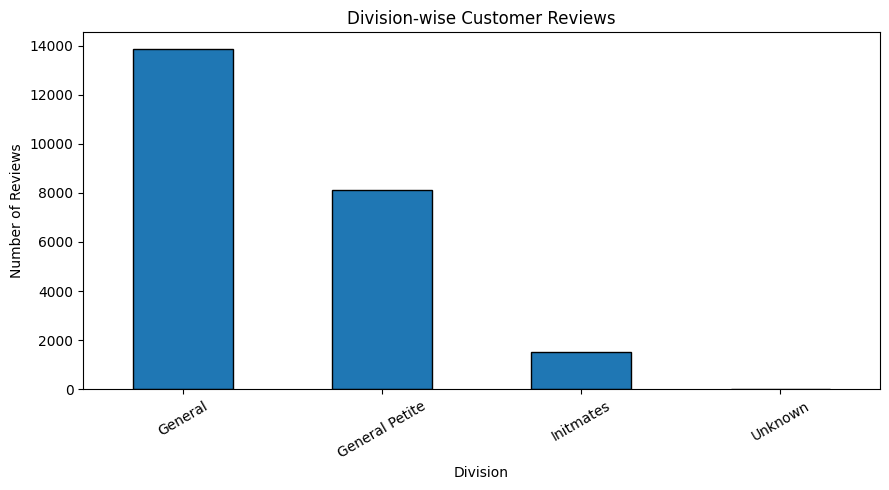

In [17]:
plt.figure(figsize=(9, 5))

division_counts.plot(kind='bar', edgecolor='black')

plt.title('Division-wise Customer Reviews')
plt.xlabel('Division')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('../outputs/division_reviews.png')
plt.show()

In [18]:
top_products = df['Clothing ID'].value_counts().head(10)

print("Top 10 Most Reviewed Products:")
print(top_products)

Top 10 Most Reviewed Products:
Clothing ID
1078    1024
862      806
1094     756
1081     582
872      545
829      527
1110     480
868      430
895      404
936      358
Name: count, dtype: int64


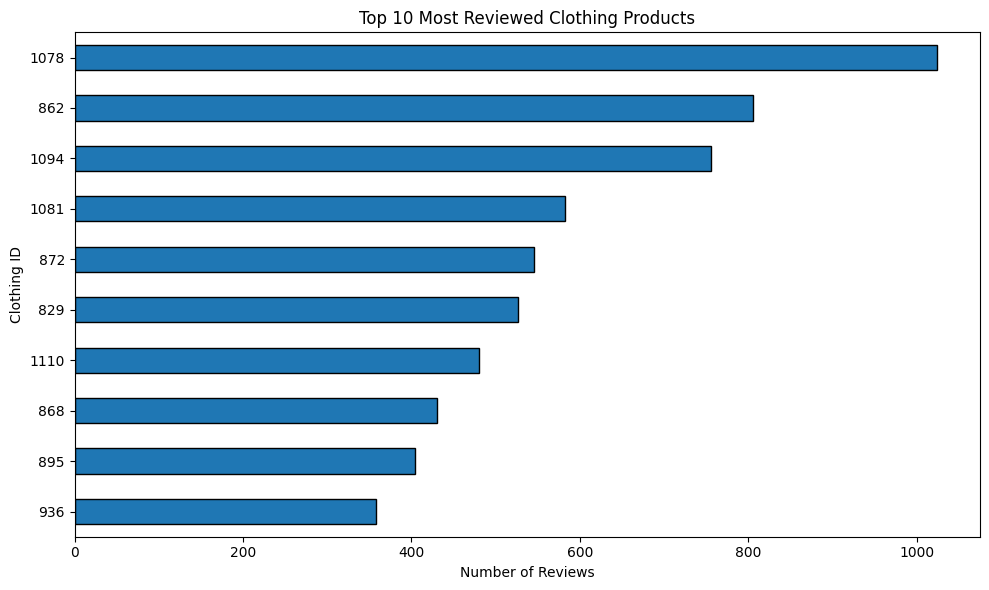

In [19]:
plt.figure(figsize=(10, 6))

top_products.sort_values().plot(kind='barh', edgecolor='black')

plt.title('Top 10 Most Reviewed Clothing Products')
plt.xlabel('Number of Reviews')
plt.ylabel('Clothing ID')

plt.tight_layout()
plt.savefig('../outputs/top_10_products.png')
plt.show()

In [20]:
department_rating = df.groupby('Department Name')['Rating'].mean().sort_values(ascending=False)

print("Average Rating by Department:")
print(department_rating.round(2))

Average Rating by Department:
Department Name
Unknown     5.00
Bottoms     4.29
Intimate    4.28
Jackets     4.26
Tops        4.17
Dresses     4.15
Trend       3.82
Name: Rating, dtype: float64


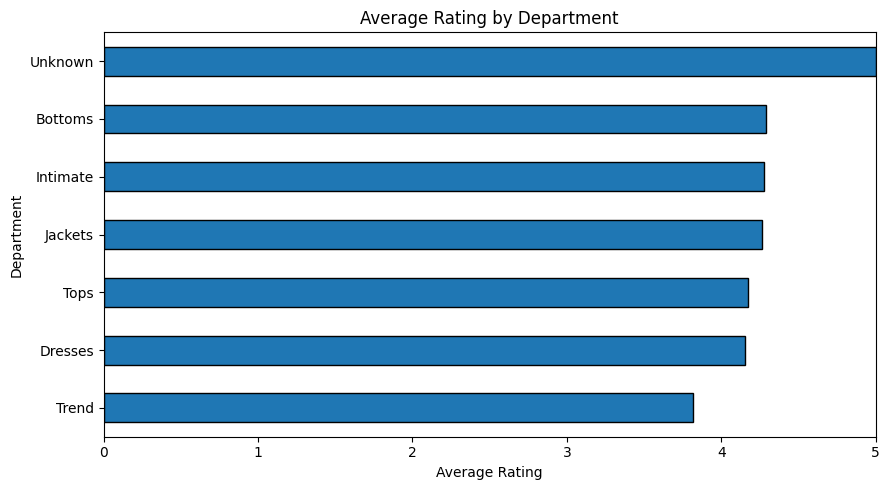

In [21]:
plt.figure(figsize=(9, 5))

department_rating.sort_values().plot(kind='barh', edgecolor='black')

plt.title('Average Rating by Department')
plt.xlabel('Average Rating')
plt.ylabel('Department')

plt.xlim(0, 5)
plt.tight_layout()

plt.savefig('../outputs/department_average_rating.png')
plt.show()

# Final Exploratory Data Analysis (EDA) Findings

1. The dataset contains 23,486 customer reviews and 10 useful columns after removing the unnecessary index column.
2. Missing values were successfully handled.
3. No duplicate records were found.
4. Most customers gave 5-star ratings.
5. Approximately 82.23% of customers recommended the products.
6. Most customers belong to the 30–45 age group.
7. Tops department received the highest number of reviews.
8. General division received the highest number of reviews.
9. Clothing ID 1078 was the most reviewed product, with 1,024 reviews.
10. Bottoms department had the highest average rating among known departments (4.29), while Trend had the lowest (3.82).

## Conclusion

The analysis shows that customer feedback is generally positive. Most customers recommended the products and gave high ratings. Tops and General received the highest number of reviews. These insights can help understand customer preferences and product performance.

In [22]:
df.to_csv('../outputs/cleaned_womens_clothing_reviews.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
